In [1]:
import sys
print(sys.executable)

import pandas, matplotlib, jupyter
print("Environment OK")

c:\Users\sehba\OneDrive - Asia Pacific University of Technology And Innovation (APU)\Documents\fraud-detector-fyp\backend\venv\Scripts\python.exe
Environment OK


In [2]:
import pandas as pd

df = pd.read_csv("../data/raw/fake_job_postings.csv")

print("Shape (rows, columns):", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

Shape (rows, columns): (17880, 18)

Column names:
['title', 'location', 'department', 'salary_range', 'company_profile', 'description', 'requirements', 'benefits', 'telecommuting', 'has_company_logo', 'has_questions', 'employment_type', 'required_experience', 'required_education', 'industry', 'function', 'fraudulent', 'in_balanced_dataset']


In [3]:
df.head(3)

,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent,in_balanced_dataset
0,Marketing Intern,"US, NY, New York",Marketing,NaN,"<h3>We're Food52, and we've created a groundbr...","<p>Food52, a fast-growing, James Beard Award-w...",<ul>\r\n<li>Experience with content management...,NaN,f,t,f,Other,Internship,NaN,NaN,Marketing,f,f
1,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"<h3>90 Seconds, the worlds Cloud Video Product...",<p>Organised - Focused - Vibrant - Awesome!<br...,<p><b>What we expect from you:</b></p>\r\n<p>Y...,<h3><b>What you will get from us</b></h3>\r\n<...,f,t,f,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,f,f
2,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,<h3></h3>\r\n<p>Valor Services provides Workfo...,"<p>Our client, located in Houston, is actively...",<ul>\r\n<li>Implement pre-commissioning and co...,NaN,f,t,f,NaN,NaN,NaN,NaN,NaN,f,f


In [4]:
print("Missing values per column:")
print(df.isnull().sum())

print("\nClass balance (fraudulent):")
print(df["fraudulent"].value_counts())
print(df["fraudulent"].value_counts(normalize=True) * 100)

Missing values per column:
title                      0
location                 346
department             11547
salary_range           15012
company_profile         3308
description                0
requirements            2689
benefits                7196
telecommuting              0
has_company_logo           0
has_questions              0
employment_type         3471
required_experience     7050
required_education      8105
industry                4903
function                6455
fraudulent                 0
in_balanced_dataset        0
dtype: int64

Class balance (fraudulent):
fraudulent
f    17014
t      866
Name: count, dtype: int64
fraudulent
f    95.1566
t     4.8434
Name: proportion, dtype: float64


In [8]:
import re

def clean_text(text):
    if not isinstance(text, str):
        text = ""
    text = text.lower()
    text = re.sub(r"<.*?>", " ", text)          # strip HTML tags (<p>, <h3>, <ul>, <li>, etc.)
    text = re.sub(r"\\r\\n|\\n|\\r", " ", text)  # strip literal escaped newlines seen in your screenshots
    text = re.sub(r"http\S+|www\S+", " ", text) # strip URLs
    text = re.sub(r"[^a-z\s]", " ", text)        # strip punctuation/numbers/special characters
    text = re.sub(r"\s+", " ", text).strip()     # collapse repeated whitespace
    return text

In [6]:
sample = df["description"].iloc[0]
print("BEFORE:\n", sample[:300])
print("\nAFTER:\n", clean_text(sample)[:300])

BEFORE:
 <p>Food52, a fast-growing, James Beard Award-winning online food community and crowd-sourced and curated recipe hub, is currently interviewing full- and part-time unpaid interns to work in a small team of editors, executives, and developers in its New York City headquarters.</p>
<ul>
<li>Reproduci

AFTER:
 food a fast growing james beard award winning online food community and crowd sourced and curated recipe hub is currently interviewing full and part time unpaid interns to work in a small team of editors executives and developers in its new york city headquarters reproducing and or repackaging exist


In [7]:
sample = df["description"].iloc[1]
print("BEFORE:\n", sample[:300])
print("\nAFTER:\n", clean_text(sample)[:300])


BEFORE:
 <p>Organised - Focused - Vibrant - Awesome!<br><br>Do you have a passion for customer service? Slick typing skills? Maybe Account Management? ...And think administration is cooler than a polar bear on a jetski? Then we need to hear you! </p>
<p>We are the Cloud Video Production Service and opperati

AFTER:
 organised focused vibrant awesome do you have a passion for customer service slick typing skills maybe account management and think administration is cooler than a polar bear on a jetski then we need to hear you we are the cloud video production service and opperating on a glodal level yeah it s pre


In [9]:
# 1. Convert label to numeric
df["fraudulent"] = df["fraudulent"].map({"f": 0, "t": 1})

# 2. Fill missing values in the text fields that make up full_text
text_cols = ["title", "company_profile", "description", "requirements", "benefits"]
for col in text_cols:
    df[col] = df[col].fillna("")

# 3. Combine into full_text, then clean
df["full_text"] = df[text_cols].agg(" ".join, axis=1)
df["clean_text"] = df["full_text"].apply(clean_text)

In [10]:
print("Unique fraudulent values after conversion:", df["fraudulent"].unique())
print("Nulls in fraudulent after conversion:", df["fraudulent"].isnull().sum())
print("Row count unchanged:", df.shape[0])
print("Nulls in clean_text:", df["clean_text"].isnull().sum())
print("Empty-string clean_text rows:", (df["clean_text"].str.strip() == "").sum())
print()
print(df[["clean_text", "fraudulent"]].sample(3, random_state=1))

Unique fraudulent values after conversion: [0 1]
Nulls in fraudulent after conversion: 0
Row count unchanged: 17880
Nulls in clean_text: 0
Empty-string clean_text rows: 0

                                              clean_text  fraudulent
5736   jr business analyst quality analyst entry leve...           0
7106   english teacher abroad we help teachers get sa...           0
11978  sql server database developer job opportunity ...           0


In [11]:
word_counts = df["clean_text"].str.split().str.len()

print(word_counts.describe())
print()
for pct in [50, 75, 90, 95, 99]:
    print(f"{pct}th percentile: {word_counts.quantile(pct/100):.0f} words")

count    17880.000000
mean       415.278691
std        312.051122
min          4.000000
25%        249.000000
50%        378.000000
75%        531.000000
max       8823.000000
Name: clean_text, dtype: float64

50th percentile: 378 words
75th percentile: 531 words
90th percentile: 700 words
95th percentile: 825 words
99th percentile: 1081 words


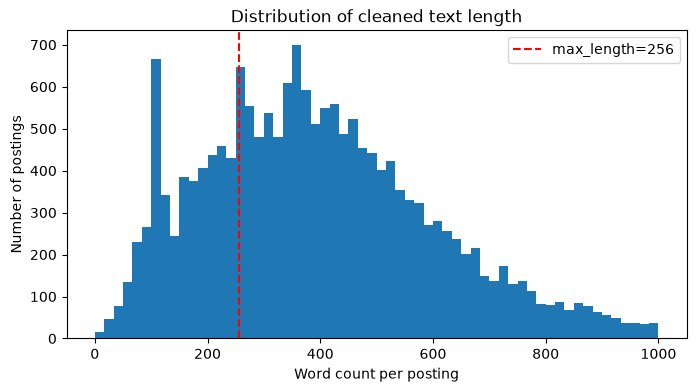

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.hist(word_counts, bins=60, range=(0, 1000))
plt.axvline(256, color="red", linestyle="--", label="max_length=256")
plt.xlabel("Word count per posting")
plt.ylabel("Number of postings")
plt.legend()
plt.title("Distribution of cleaned text length")
plt.show()

In [13]:
from transformers import BertTokenizerFast
import numpy as np

tokenizer = BertTokenizerFast.from_pretrained("bert-base-uncased")

# Sample 2000 rows for a fast but statistically solid estimate
sample_texts = df["clean_text"].sample(2000, random_state=42).tolist()
token_lengths = np.array([len(tokenizer.tokenize(t)) for t in sample_texts])

print("Token length stats (sample of 2000 postings):")
print(f"  mean: {token_lengths.mean():.0f}")
print(f"  median: {np.median(token_lengths):.0f}")
print(f"  % exceeding 512 tokens: {(token_lengths > 512).mean()*100:.1f}%")
print(f"  % exceeding 256 tokens: {(token_lengths > 256).mean()*100:.1f}%")

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

c:\Users\sehba\OneDrive - Asia Pacific University of Technology And Innovation (APU)\Documents\fraud-detector-fyp\backend\venv\Lib\site-packages\huggingface_hub\file_download.py:139: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\sehba\.cache\huggingface\hub\models--bert-base-uncased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (517 > 512). Running this sequence through the model will result in indexing errors


Token length stats (sample of 2000 postings):
  mean: 439
  median: 397
  % exceeding 512 tokens: 31.6%
  % exceeding 256 tokens: 74.9%


In [14]:
genuine_count = (df["fraudulent"] == 0).sum()
fraud_count = (df["fraudulent"] == 1).sum()

weight_genuine = 1.0
weight_fraud = genuine_count / fraud_count

print(f"Genuine postings: {genuine_count}")
print(f"Fraudulent postings: {fraud_count}")
print(f"Class weight (genuine): {weight_genuine:.2f}")
print(f"Class weight (fraudulent): {weight_fraud:.2f}")

Genuine postings: 17014
Fraudulent postings: 866
Class weight (genuine): 1.00
Class weight (fraudulent): 19.65


In [15]:
from sklearn.model_selection import train_test_split

# First split off the test set (15% of total)
train_val_df, test_df = train_test_split(
    df, test_size=0.15, stratify=df["fraudulent"], random_state=42
)

# Split remaining 85% into train (70% of total) and val (15% of total)
val_fraction_of_remaining = 0.15 / 0.85  # ensures val ends up as exactly 15% of the ORIGINAL total
train_df, val_df = train_test_split(
    train_val_df, test_size=val_fraction_of_remaining,
    stratify=train_val_df["fraudulent"], random_state=42
)

print(f"Train: {len(train_df)} rows ({len(train_df)/len(df)*100:.2f}%)")
print(f"Val:   {len(val_df)} rows ({len(val_df)/len(df)*100:.2f}%)")
print(f"Test:  {len(test_df)} rows ({len(test_df)/len(df)*100:.2f}%)")

Train: 12516 rows (70.00%)
Val:   2682 rows (15.00%)
Test:  2682 rows (15.00%)


In [16]:
for name, split_df in [("Train", train_df), ("Val", val_df), ("Test", test_df)]:
    fraud_count = split_df["fraudulent"].sum()
    fraud_pct = split_df["fraudulent"].mean() * 100
    print(f"{name}: {fraud_count} fraudulent / {len(split_df)} total ({fraud_pct:.2f}%)")

Train: 606 fraudulent / 12516 total (4.84%)
Val: 130 fraudulent / 2682 total (4.85%)
Test: 130 fraudulent / 2682 total (4.85%)


In [17]:
import os
os.makedirs("../data/processed", exist_ok=True)

cols_to_save = ["title", "clean_text", "fraudulent"]

train_df[cols_to_save].to_csv("../data/processed/train.csv", index_label="original_index")
val_df[cols_to_save].to_csv("../data/processed/val.csv", index_label="original_index")
test_df[cols_to_save].to_csv("../data/processed/test.csv", index_label="original_index")

print("Saved train.csv, val.csv, test.csv to ml/data/processed/")

Saved train.csv, val.csv, test.csv to ml/data/processed/


In [18]:
check = pd.read_csv("../data/processed/train.csv")
print(check.shape)
print(check.head(2))

(12516, 4)
   original_index                          title  \
0            4086              Technical Manager   
1            4740  iOS developer job description   

                                          clean_text  fraudulent  
0  technical manager luxury british cocoa grower ...           0  
1  ios developer job description we are looking f...           0  
